# 03. Proposed Method: Adaptive TC Annealing with Deterministic Mean Decorrelation (AdaTC-DIP-VAE)

This notebook implements, trains, and comprehensively benchmarks the proposed **AdaTC-DIP-VAE** model on the dSprites dataset.

---

### Core Theoretical Motivation & Gaps Addressed

#### 1. The Static TC Repulsion Problem (Gap 3)
As established by Burgess et al. (2018), generative factors emerge hierarchically during training:
$$\text{Position } (X, Y) \longrightarrow \text{Scale} \longrightarrow \text{Shape} \longrightarrow \text{Orientation}$$
Applying a static penalty $\beta \gg 1$ from step 0 repels dimensions before the decoder has established basic spatial reconstruction filters. This causes premature posterior collapse into "dead dimensions".

**Solution: Principled Cosine TC Annealing $\beta(t)$**:
$$\beta(t) = \begin{cases} 
1 + \frac{\beta_{\text{target}} - 1}{2} \left[ 1 - \cos\left( \frac{\pi t}{T_{\text{warm}}} \right) \right], & \text{if } 0 \le t < T_{\text{warm}} \\
\beta_{\text{target}}, & \text{if } t \ge T_{\text{warm}}
\end{cases}$$
- At $t=0$: $\beta(0) = 1$ and $\beta'(0) = 0$ (smooth start with standard unconstrained ELBO).
- Smooth monotonic ramp up to $\beta_{\text{target}} = 6.0$ over $T_{\text{warm}}$ steps.

#### 2. The Sampled $q(z)$ vs. Mean $\mu_\phi(x)$ Disconnect (Gap 4)
Downstream disentanglement metrics (MIG, DCI, FactorVAE Score) exclusively evaluate the **deterministic encoder means** $\mu_\phi(x)$ (Locatello et al., 2019). By the Law of Total Covariance (Kumar et al., 2018, Eq. 5):
$$\text{Cov}_{q(z)}[z] = \mathbb{E}_{p(x)}[\Sigma_\phi(x)] + \text{Cov}_{p(x)}[\mu_\phi(x)]$$
Models can artificially lower Total Correlation on sampled $z$ simply by inflating posterior variances $\Sigma_\phi(x)$ with Gaussian noise, while the underlying representations $\mu_\phi(x)$ remain entangled!

**Solution: Anchored Mean Covariance Penalty $\mathcal{P}_{\text{cov}}(\mu)$**:
$$\mathcal{P}_{\text{cov}}(\mu_\phi) = \lambda_{\text{od}} \sum_{i \ne j} [\text{Cov}(\mu_\phi)]_{ij}^2 + \lambda_{\text{d}} \sum_{i} ([\text{Cov}(\mu_\phi)]_{ii} - 1.0)^2$$
with $\lambda_{\text{od}} = 10.0$ and $\lambda_{\text{d}} = 1.0$.

---

### Complete Unified Objective:
$$\mathcal{L}_{\text{AdaTC-DIP}}(t) = \mathcal{L}_{\text{ELBO}} - (\beta(t) - 1) \text{TC}(z) - \mathcal{P}_{\text{cov}}(\mu_\phi)$$

---

### Key Capabilities:
- Drop-in ready for Kaggle/Colab with auto-detected GPU/MPS/CPU.
- Auto-downloading dSprites dataset.
- `FAST_MODE = True` toggle (50k samples, 15 epochs, $T_{\text{warm}} = 5000$).
- Tracks TC dynamics, reconstruction loss, and covariance Frobenius norm.
- Evaluates MIG, DCI, FactorVAE Score, and Reconstruction MSE.
- Saves `training_dynamics_proposed.png`, `results_proposed.csv`, and `traversals_proposed.png`.



In [1]:
import os
import sys
import time
import math
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

# Auto-detect device: CUDA -> MPS -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"[Device] Using NVIDIA CUDA GPU: {torch.cuda.get_device_name(0)}")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
    print("[Device] Using Apple Silicon MPS Acceleration")
else:
    device = torch.device("cpu")
    print("[Device] Using CPU")

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
print(f"[Config] Random seed set to {SEED}")



[Device] Using NVIDIA CUDA GPU: Tesla T4
[Config] Random seed set to 42


In [2]:
# ==========================================
# EXPERIMENT CONFIGURATION
# ==========================================
# FAST_MODE = True: trains on 50,000 samples for 15 epochs (~5-8 mins on T4 GPU)
# FAST_MODE = False: trains on all 737,280 samples for 25 epochs
FAST_MODE = True

BATCH_SIZE = 256
EPOCHS = 15 if FAST_MODE else 25
NUM_TRAIN_SAMPLES = 50000 if FAST_MODE else 727280
NUM_EVAL_SAMPLES = 5000 if FAST_MODE else 10000
LATENT_DIM = 10
LEARNING_RATE = 5e-4

# Proposed AdaTC-DIP-VAE Hyperparameters
BETA_TARGET = 6.0
WARMUP_STEPS = 5000 if FAST_MODE else 15000
LAMBDA_OD = 10.0   # Off-diagonal covariance penalty
LAMBDA_D = 1.0     # Diagonal variance anchoring penalty

print("AdaTC-DIP-VAE Proposed Objective Settings:")
print(f"  FAST_MODE:         {FAST_MODE}")
print(f"  Beta Target:       {BETA_TARGET}")
print(f"  Warmup Steps:      {WARMUP_STEPS}")
print(f"  Lambda Off-Diag:   {LAMBDA_OD}")
print(f"  Lambda Diag:       {LAMBDA_D}")
print(f"  Batch Size:        {BATCH_SIZE}")
print(f"  Epochs:            {EPOCHS}")
print(f"  Training Samples:  {NUM_TRAIN_SAMPLES}")
print(f"  Evaluation Samples:{NUM_EVAL_SAMPLES}")
print(f"  Latent Dimensions: {LATENT_DIM}")
print(f"  Learning Rate:     {LEARNING_RATE}")



AdaTC-DIP-VAE Proposed Objective Settings:
  FAST_MODE:         True
  Beta Target:       6.0
  Warmup Steps:      5000
  Lambda Off-Diag:   10.0
  Lambda Diag:       1.0
  Batch Size:        256
  Epochs:            15
  Training Samples:  50000
  Evaluation Samples:5000
  Latent Dimensions: 10
  Learning Rate:     0.0005


In [3]:
def get_dsprites_filepath():
    filename = "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
    search_paths = [
        os.path.join(".", filename),
        os.path.join(".", "data", filename),
        os.path.join("..", filename),
        os.path.join("..", "data", filename),
        os.path.join("/kaggle/input/dsprites-dataset", filename),
        os.path.join("/kaggle/input/dsprites", filename),
        os.path.join("/content", filename),
        os.path.join("/content/data", filename)
    ]
    for p in search_paths:
        if os.path.exists(p):
            return p
    return None

def download_dsprites(target_dir="./data"):
    filename = "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
    os.makedirs(target_dir, exist_ok=True)
    target_path = os.path.join(target_dir, filename)
    url = "https://github.com/google-deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
    print(f"[Dataset] Downloading dSprites dataset from {url}...")
    
    def reporthook(block_num, block_size, total_size):
        if block_num % 1000 == 0:
            downloaded = block_num * block_size
            if total_size > 0:
                percent = downloaded * 100 / total_size
                print(f"  Progress: {percent:.1f}% ({downloaded / (1024*1024):.1f} MB / {total_size / (1024*1024):.1f} MB)")
            else:
                print(f"  Downloaded: {downloaded / (1024*1024):.1f} MB")
                
    urllib.request.urlretrieve(url, target_path, reporthook=reporthook)
    print(f"[Dataset] Download complete: {target_path}")
    return target_path

# Load dSprites
filepath = get_dsprites_filepath()
if filepath is None:
    filepath = download_dsprites()

print(f"[Dataset] Loading data from {filepath}...")
raw_data = np.load(filepath, allow_pickle=True, encoding="latin1")
all_imgs = raw_data["imgs"]  # (737280, 64, 64), uint8
all_latents_classes = raw_data["latents_classes"]  # (737280, 6)
all_latents_values = raw_data["latents_values"]  # (737280, 6)
print(f"[Dataset] Successfully loaded {len(all_imgs)} images of shape {all_imgs.shape[1:]}.")

# Split into train and evaluation subsets
np.random.seed(SEED)
shuffled_idx = np.random.permutation(len(all_imgs))
train_indices = shuffled_idx[:NUM_TRAIN_SAMPLES]
eval_indices = shuffled_idx[NUM_TRAIN_SAMPLES:NUM_TRAIN_SAMPLES + NUM_EVAL_SAMPLES]

train_imgs = all_imgs[train_indices]
train_classes = all_latents_classes[train_indices]
eval_imgs = all_imgs[eval_indices]
eval_classes = all_latents_classes[eval_indices]

class DSpritesDataset(Dataset):
    def __init__(self, imgs, latents_classes):
        self.imgs = torch.from_numpy(imgs).float().unsqueeze(1)
        self.latents_classes = torch.from_numpy(latents_classes).long()

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        return self.imgs[idx], self.latents_classes[idx]

train_dataset = DSpritesDataset(train_imgs, train_classes)
eval_dataset = DSpritesDataset(eval_imgs, eval_classes)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"[Dataset] Train batches: {len(train_loader)} | Eval batches: {len(eval_loader)}")



[Dataset] Downloading dSprites dataset from https://github.com/google-deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz...
  Progress: 0.0% (0.0 MB / 18.4 MB)
  Progress: 42.4% (7.8 MB / 18.4 MB)
  Progress: 84.8% (15.6 MB / 18.4 MB)
[Dataset] Download complete: ./data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
[Dataset] Loading data from ./data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz...
[Dataset] Successfully loaded 737280 images of shape (64, 64).
[Dataset] Train batches: 195 | Eval batches: 20


In [4]:
class ConvVAE(nn.Module):
    """
    Standard ConvVAE architecture for 64x64 binary images (Chen et al. 2018, Locatello et al. 2019).
    """
    def __init__(self, latent_dim=10):
        super(ConvVAE, self).__init__()
        self.latent_dim = latent_dim
        
        # Encoder: 4 convolutional layers
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # (B, 32, 32, 32)
            nn.ReLU(True),
            nn.Conv2d(32, 32, kernel_size=4, stride=2, padding=1),  # (B, 32, 16, 16)
            nn.ReLU(True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # (B, 64, 8, 8)
            nn.ReLU(True),
            nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1),  # (B, 64, 4, 4)
            nn.ReLU(True)
        )
        self.fc_enc = nn.Linear(64 * 4 * 4, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        
        # Decoder: linear layers + 4 transposed convolutions
        self.fc_dec = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(True),
            nn.Linear(256, 64 * 4 * 4),
            nn.ReLU(True)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1), # (B, 64, 8, 8)
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), # (B, 32, 16, 16)
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2, padding=1), # (B, 32, 32, 32)
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1)   # (B, 1, 64, 64)
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        h = F.relu(self.fc_enc(h))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_dec(z)
        h = h.view(h.size(0), 64, 4, 4)
        recon_logits = self.decoder(h)
        return recon_logits

    def decode_probs(self, z):
        logits = self.decode(z)
        return torch.sigmoid(logits)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_logits = self.decode(z)
        return recon_logits, mu, logvar, z



In [5]:
def get_beta(step, warmup_steps, beta_target=6.0):
    """
    Cosine annealing schedule for Total Correlation penalty beta(t):
    beta(t) = 1 + ((beta_target - 1) / 2) * (1 - cos(pi * min(t, T_warm) / T_warm))
    """
    if step >= warmup_steps:
        return float(beta_target)
    cos_val = math.cos(math.pi * step / warmup_steps)
    return 1.0 + ((beta_target - 1.0) / 2.0) * (1.0 - cos_val)

def compute_cov_penalty(mu, lambda_od=10.0, lambda_d=1.0):
    """
    Computes the DIP-VAE-I covariance penalty on encoder means:
    lambda_od * sum_{i != j} Cov_ij^2 + lambda_d * sum_i (Cov_ii - 1)^2
    """
    M = mu.size(0)
    if M <= 1:
        zero = torch.tensor(0.0, device=mu.device)
        return zero, zero
        
    mu_centered = mu - mu.mean(dim=0, keepdim=True)
    cov = (mu_centered.t() @ mu_centered) / (M - 1)
    
    cov_diag = torch.diag(cov)
    cov_off = cov - torch.diag(cov_diag)
    
    # Off-diagonal penalty
    p_od = torch.sum(cov_off ** 2)
    # Diagonal anchoring penalty
    p_d = torch.sum((cov_diag - 1.0) ** 2)
    
    total_penalty = lambda_od * p_od + lambda_d * p_d
    cov_off_norm = torch.sqrt(p_od + 1e-8)
    
    return total_penalty, cov_off_norm



In [6]:
def compute_mws_tc(z, mu, logvar, dataset_size):
    """
    Computes Total Correlation via Minibatch Weighted Sampling (MWS) (Chen et al., 2018).
    z: sampled latents (M, d)
    mu: encoder means (M, d)
    logvar: encoder log-variances (M, d)
    dataset_size: total training dataset size N
    """
    M, d = z.size()
    
    # Pairwise log Gaussian density: log q(z_i | x_k)
    # diff: (M, M, d), var: (1, M, d)
    diff = z.unsqueeze(1) - mu.unsqueeze(0)
    var = logvar.exp().unsqueeze(0)
    log_q_zx_per_dim = -0.5 * (math.log(2.0 * math.pi) + logvar.unsqueeze(0) + (diff ** 2) / (var + 1e-8))
    
    # Joint log q(z_i | x_k): sum over dimensions d -> (M, M)
    log_q_zx = log_q_zx_per_dim.sum(dim=2)
    
    # Aggregated log q(z_i): logsumexp over k -> (M,)
    log_qz = torch.logsumexp(log_q_zx, dim=1) - math.log(M * dataset_size)
    
    # Marginal log q(z_ij): logsumexp over k -> (M, d)
    log_qz_j = torch.logsumexp(log_q_zx_per_dim, dim=1) - math.log(M * dataset_size)
    log_qz_prod = log_qz_j.sum(dim=1)  # sum over latent dimensions -> (M,)
    
    # Total Correlation: E_q(z) [ log q(z) - sum_j log q(z_j) ]
    tc = (log_qz - log_qz_prod).mean()
    
    # Mutual Information: E_q(z,x) [ log q(z|x) - log q(z) ]
    log_q_z_given_x = -0.5 * (math.log(2.0 * math.pi) + logvar + ((z - mu) ** 2) / (logvar.exp() + 1e-8)).sum(dim=1)
    mi = (log_q_z_given_x - log_qz).mean()
    
    # Dimension-wise KL: E_q(z) [ sum_j (log q(z_j) - log p(z_j)) ]
    log_pz = -0.5 * (math.log(2.0 * math.pi) + z ** 2).sum(dim=1)
    dw_kl = (log_qz_prod - log_pz).mean()
    
    return tc, mi, dw_kl



In [7]:
@torch.no_grad()
def compute_reconstruction_mse(model, eval_loader, device):
    """Computes mean squared error between reconstructed and original images."""
    model.eval()
    total_mse = 0.0
    total_samples = 0
    for x, _ in eval_loader:
        x = x.to(device)
        mu, _ = model.encode(x)
        recon = model.decode_probs(mu)
        mse = torch.mean((recon - x) ** 2, dim=[1, 2, 3]).sum().item()
        total_mse += mse
        total_samples += x.size(0)
    return total_mse / total_samples

def compute_mig(latents, factor_classes, num_bins=20):
    """
    Computes Mutual Information Gap (MIG) (Chen et al., 2018).
    latents: np.ndarray (N, d)
    factor_classes: np.ndarray (N, K)
    """
    N, d = latents.shape
    K = factor_classes.shape[1]
    
    # Discretize continuous latents into bins
    discretized = np.zeros_like(latents, dtype=int)
    for j in range(d):
        hist, bin_edges = np.histogram(latents[:, j], bins=num_bins)
        discretized[:, j] = np.clip(np.digitize(latents[:, j], bin_edges[:-1]) - 1, 0, num_bins - 1)
        
    mi_matrix = np.zeros((d, K))
    factor_entropies = np.zeros(K)
    
    for k in range(K):
        fk = factor_classes[:, k]
        unique_f, counts_f = np.unique(fk, return_counts=True)
        if len(unique_f) <= 1:
            factor_entropies[k] = 0.0
            continue
        prob_f = counts_f / N
        factor_entropies[k] = -np.sum(prob_f * np.log(prob_f + 1e-12))
        
        for j in range(d):
            zj = discretized[:, j]
            joint_counts = np.histogram2d(zj, fk, bins=[num_bins, len(unique_f)])[0]
            joint_p = joint_counts / N
            p_z = joint_p.sum(axis=1, keepdims=True)
            p_v = joint_p.sum(axis=0, keepdims=True)
            nz = joint_p > 0
            mi = np.sum(joint_p[nz] * np.log(joint_p[nz] / (p_z @ p_v)[nz] + 1e-12))
            mi_matrix[j, k] = max(0.0, mi)
            
    active_factors = [k for k in range(K) if factor_entropies[k] > 1e-6]
    if len(active_factors) == 0:
        return 0.0
        
    gaps = []
    for k in active_factors:
        sorted_mi = np.sort(mi_matrix[:, k])[::-1]
        gap = (sorted_mi[0] - sorted_mi[1]) / factor_entropies[k]
        gaps.append(gap)
        
    return float(np.mean(gaps))

def compute_factorvae_score(model, dataset_imgs, dataset_classes, device, num_train=800, num_eval=800, batch_size=64):
    """
    Computes FactorVAE metric score (Kim & Mnih, 2018).
    """
    model.eval()
    active_factor_indices = [1, 2, 3, 4, 5]  # shape, scale, orientation, posX, posY
    num_factors = len(active_factor_indices)
    
    # Estimate global standard deviation for each latent dimension
    sample_size = min(5000, len(dataset_imgs))
    sample_indices = np.random.choice(len(dataset_imgs), size=sample_size, replace=False)
    with torch.no_grad():
        sample_x = torch.from_numpy(dataset_imgs[sample_indices]).float().unsqueeze(1).to(device)
        sample_mu, _ = model.encode(sample_x)
        global_std = torch.std(sample_mu, dim=0).cpu().numpy()
        
    active_dims = np.where(global_std > 0.05)[0]
    if len(active_dims) == 0:
        active_dims = np.arange(sample_mu.size(1))
    global_std[global_std < 1e-8] = 1.0

    def generate_batch_votes(num_votes):
        votes = []
        targets = []
        for _ in range(num_votes):
            k_idx = np.random.choice(num_factors)
            k = active_factor_indices[k_idx]
            val = np.random.choice(np.unique(dataset_classes[:, k]))
            matching = np.where(dataset_classes[:, k] == val)[0]
            
            replace = len(matching) < batch_size
            chosen = np.random.choice(matching, size=batch_size, replace=replace)
            
            with torch.no_grad():
                xb = torch.from_numpy(dataset_imgs[chosen]).float().unsqueeze(1).to(device)
                mu_b, _ = model.encode(xb)
                mu_b = mu_b.cpu().numpy()
                
            norm_var = np.var(mu_b / global_std, axis=0)
            dim_min_var = active_dims[np.argmin(norm_var[active_dims])]
            votes.append(dim_min_var)
            targets.append(k_idx)
            
        return np.array(votes), np.array(targets)

    train_votes, train_targets = generate_batch_votes(num_train)
    eval_votes, eval_targets = generate_batch_votes(num_eval)
    
    dim_to_factor = {}
    for d_idx in np.unique(train_votes):
        factor_votes = train_targets[train_votes == d_idx]
        dim_to_factor[d_idx] = np.bincount(factor_votes).argmax()
        
    predictions = np.array([dim_to_factor.get(d, 0) for d in eval_votes])
    accuracy = float(np.mean(predictions == eval_targets))
    return accuracy

def compute_dci(latents, factor_classes):
    """
    Computes DCI Disentanglement score (Eastwood & Williams, 2018; Locatello et al., 2019).
    latents: np.ndarray (N, d)
    factor_classes: np.ndarray (N, K)
    """
    N, d = latents.shape
    active_k = [k for k in range(factor_classes.shape[1]) if len(np.unique(factor_classes[:, k])) > 1]
    K = len(active_k)
    if K == 0:
        return 0.0
        
    importance_matrix = np.zeros((d, K))
    
    for idx, k in enumerate(active_k):
        y = factor_classes[:, k]
        num_classes = len(np.unique(y))
        if num_classes <= 5:
            clf = GradientBoostingClassifier(n_estimators=40, max_depth=3, random_state=42)
        else:
            clf = GradientBoostingRegressor(n_estimators=40, max_depth=3, random_state=42)
        clf.fit(latents, y)
        importance_matrix[:, idx] = clf.feature_importances_
        
    row_sums = importance_matrix.sum(axis=1)
    disentanglement_per_dim = np.zeros(d)
    
    for j in range(d):
        if row_sums[j] > 1e-12:
            p_jk = importance_matrix[j, :] / row_sums[j]
            nz = p_jk > 0
            entropy = -np.sum(p_jk[nz] * np.log(p_jk[nz])) / np.log(K) if K > 1 else 0.0
            disentanglement_per_dim[j] = 1.0 - entropy
        else:
            disentanglement_per_dim[j] = 0.0
            
    total_importance = row_sums.sum()
    if total_importance > 1e-12:
        weights = row_sums / total_importance
        return float(np.sum(weights * disentanglement_per_dim))
    return 0.0

@torch.no_grad()
def extract_eval_latents(model, eval_loader, device):
    """Extracts deterministic encoder means mu for the evaluation dataset."""
    model.eval()
    all_mu = []
    for x, _ in eval_loader:
        x = x.to(device)
        mu, _ = model.encode(x)
        all_mu.append(mu.cpu().numpy())
    return np.concatenate(all_mu, axis=0)



In [8]:
def plot_latent_traversals(models_dict, sample_img, device, num_steps=7, val_range=(-3.0, 3.0), save_path=None):
    """
    Visualizes latent traversals across coordinates for given models.
    """
    if isinstance(sample_img, np.ndarray):
        sample_img = torch.from_numpy(sample_img).float()
    if sample_img.dim() == 2:
        sample_img = sample_img.unsqueeze(0).unsqueeze(0)
    elif sample_img.dim() == 3:
        sample_img = sample_img.unsqueeze(0)
    sample_img = sample_img.to(device)
    
    traversal_vals = np.linspace(val_range[0], val_range[1], num_steps)
    
    for model_name, model in models_dict.items():
        model.eval()
        with torch.no_grad():
            mu, _ = model.encode(sample_img)
            d = mu.size(1)
            
            fig, axes = plt.subplots(d, num_steps, figsize=(num_steps * 1.4, d * 1.4))
            fig.suptitle(f"Latent Traversals: {model_name}", fontsize=15, y=0.99)
            
            for j in range(d):
                for s, val in enumerate(traversal_vals):
                    z = mu.clone()
                    z[0, j] = val
                    recon = model.decode_probs(z)
                    img = recon[0, 0].cpu().numpy()
                    
                    ax = axes[j, s] if d > 1 else axes[s]
                    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
                    ax.axis("off")
                    if s == 0:
                        ax.text(-0.3, 0.5, f"z_{j}", transform=ax.transAxes,
                                verticalalignment="center", fontsize=11, fontweight="bold")
                        
            plt.tight_layout()
            if save_path:
                suffix = model_name.replace(" ", "_").replace("(", "").replace(")", "").replace("=", "").lower()
                save_file = save_path if len(models_dict) == 1 else save_path.replace(".png", f"_{suffix}.png")
                plt.savefig(save_file, bbox_inches="tight", dpi=150)
                print(f"[Plot] Saved traversal figure: {save_file}")
            plt.show()
            plt.close()



In [9]:
def train_adatc_dip_vae(train_loader, beta_target=6.0, warmup_steps=5000,
                        lambda_od=10.0, lambda_d=1.0, epochs=15, lr=5e-4, device=device):
    print(f"\n==========================================")
    print(f"Starting Training: AdaTC-DIP-VAE (Proposed)")
    print(f"  Beta Target: {beta_target} | Warmup: {warmup_steps} steps")
    print(f"  Lambda OD: {lambda_od} | Lambda D: {lambda_d}")
    print(f"==========================================")
    model = ConvVAE(latent_dim=LATENT_DIM).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    N_train = len(train_loader.dataset)
    
    history = {
        "steps": [],
        "beta": [],
        "recon_loss": [],
        "tc": [],
        "cov_norm": [],
        "total_loss": []
    }
    
    global_step = 0
    start_time = time.time()
    
    for epoch in range(1, epochs + 1):
        model.train()
        epoch_recon = 0.0
        epoch_kl = 0.0
        epoch_tc = 0.0
        epoch_cov = 0.0
        epoch_loss = 0.0
        num_batches = 0
        
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            
            recon_logits, mu, logvar, z = model(x)
            
            # Reconstruction loss (Bernoulli NLL)
            recon_loss = F.binary_cross_entropy_with_logits(recon_logits, x, reduction='none').sum(dim=(1, 2, 3)).mean()
            
            # Analytical Gaussian KL
            kl_loss = 0.5 * torch.sum(mu.pow(2) + logvar.exp() - 1.0 - logvar, dim=1).mean()
            
            # Minibatch Weighted Sampling (MWS) for Total Correlation
            tc, mi, dw_kl = compute_mws_tc(z, mu, logvar, dataset_size=N_train)
            
            # Adaptive Beta(t) via Cosine Annealing
            beta_t = get_beta(global_step, warmup_steps, beta_target=beta_target)
            
            # Anchored Mean Covariance Penalty
            cov_penalty, cov_norm = compute_cov_penalty(mu, lambda_od=lambda_od, lambda_d=lambda_d)
            
            # Unified Proposed Objective
            loss = recon_loss + kl_loss + (beta_t - 1.0) * tc + cov_penalty
            loss.backward()
            optimizer.step()
            
            epoch_recon += recon_loss.item()
            epoch_kl += kl_loss.item()
            epoch_tc += tc.item()
            epoch_cov += cov_norm.item()
            epoch_loss += loss.item()
            num_batches += 1
            
            # Record history every 10 steps
            if global_step % 10 == 0:
                history["steps"].append(global_step)
                history["beta"].append(beta_t)
                history["recon_loss"].append(recon_loss.item())
                history["tc"].append(tc.item())
                history["cov_norm"].append(cov_norm.item())
                history["total_loss"].append(loss.item())
                
            global_step += 1
            
        avg_recon = epoch_recon / num_batches
        avg_kl = epoch_kl / num_batches
        avg_tc = epoch_tc / num_batches
        avg_cov = epoch_cov / num_batches
        avg_loss = epoch_loss / num_batches
        curr_beta = get_beta(global_step, warmup_steps, beta_target)
        elapsed = time.time() - start_time
        
        if epoch % 2 == 0 or epoch == epochs or epoch == 1:
            print(f"Epoch [{epoch:02d}/{epochs:02d}] | Recon: {avg_recon:.2f} | KL: {avg_kl:.2f} | TC: {avg_tc:.2f} | CovNorm: {avg_cov:.3f} | Beta: {curr_beta:.2f} | Loss: {avg_loss:.2f} | Time: {elapsed:.1f}s")
            
    print(f"[Finished] AdaTC-DIP-VAE trained in {time.time() - start_time:.1f}s ({global_step} total steps)")
    return model, history



In [10]:
model_adatc_dip, train_history = train_adatc_dip_vae(
    train_loader=train_loader,
    beta_target=BETA_TARGET,
    warmup_steps=WARMUP_STEPS,
    lambda_od=LAMBDA_OD,
    lambda_d=LAMBDA_D,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    device=device
)




Starting Training: AdaTC-DIP-VAE (Proposed)
  Beta Target: 6.0 | Warmup: 5000 steps
  Lambda OD: 10.0 | Lambda D: 1.0
Epoch [01/15] | Recon: 783.08 | KL: 4.83 | TC: 97.38 | CovNorm: 0.007 | Beta: 1.02 | Loss: 798.51 | Time: 15.5s
Epoch [02/15] | Recon: 574.92 | KL: 0.02 | TC: 97.38 | CovNorm: 0.000 | Beta: 1.07 | Loss: 589.18 | Time: 20.9s
Epoch [04/15] | Recon: 198.70 | KL: 19.81 | TC: 107.29 | CovNorm: 0.612 | Beta: 1.29 | Loss: 252.79 | Time: 31.7s
Epoch [06/15] | Recon: 97.71 | KL: 18.38 | TC: 107.08 | CovNorm: 0.310 | Beta: 1.65 | Loss: 180.61 | Time: 42.4s
Epoch [08/15] | Recon: 82.60 | KL: 16.60 | TC: 106.99 | CovNorm: 0.316 | Beta: 2.11 | Loss: 209.52 | Time: 53.3s
Epoch [10/15] | Recon: 80.86 | KL: 15.08 | TC: 105.98 | CovNorm: 0.313 | Beta: 2.65 | Loss: 260.87 | Time: 64.4s
Epoch [12/15] | Recon: 80.74 | KL: 13.97 | TC: 105.09 | CovNorm: 0.321 | Beta: 3.25 | Loss: 319.91 | Time: 75.6s
Epoch [14/15] | Recon: 81.37 | KL: 13.14 | TC: 104.37 | CovNorm: 0.326 | Beta: 3.86 | Loss:

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Cosine Annealing Schedule beta(t)
axes[0].plot(train_history["steps"], train_history["beta"], color='tab:blue', lw=2)
axes[0].set_title("Cosine TC Annealing Schedule $\\beta(t)$", fontsize=13)
axes[0].set_xlabel("Training Step")
axes[0].set_ylabel("$\\beta(t)$")
axes[0].grid(True, alpha=0.3)

# Subplot 2: Total Correlation vs Reconstruction Loss
ax2_twin = axes[1].twinx()
l1 = axes[1].plot(train_history["steps"], train_history["recon_loss"], color='tab:red', lw=1.5, label="Recon Loss")
l2 = ax2_twin.plot(train_history["steps"], train_history["tc"], color='tab:purple', lw=1.5, label="Total Correlation")
axes[1].set_title("Reconstruction Loss & TC Dynamics", fontsize=13)
axes[1].set_xlabel("Training Step")
axes[1].set_ylabel("Reconstruction Loss (NLL)", color='tab:red')
ax2_twin.set_ylabel("Total Correlation $TC(z)$", color='tab:purple')
axes[1].grid(True, alpha=0.3)

# Subplot 3: Off-Diagonal Mean Covariance Norm
axes[2].plot(train_history["steps"], train_history["cov_norm"], color='tab:green', lw=1.5)
axes[2].set_title("Off-Diagonal Mean Covariance Norm $\\|C_{\\text{off}}\\|_F$", fontsize=13)
axes[2].set_xlabel("Training Step")
axes[2].set_ylabel("Frobenius Norm")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
dynamics_save_path = "training_dynamics_proposed.png"
plt.savefig(dynamics_save_path, dpi=150)
print(f"[Plot] Training dynamics saved to: {dynamics_save_path}")
plt.show()



[Plot] Training dynamics saved to: training_dynamics_proposed.png


In [12]:
print("\n==========================================")
print("Evaluating AdaTC-DIP-VAE Disentanglement Benchmarks")
print("==========================================")

# Extract evaluation latents
print("[1/4] Extracting validation representations...")
mu_proposed = extract_eval_latents(model_adatc_dip, eval_loader, device)

# 1. Reconstruction MSE
print("[2/4] Computing Reconstruction MSE...")
mse_proposed = compute_reconstruction_mse(model_adatc_dip, eval_loader, device)

# 2. Mutual Information Gap (MIG)
print("[3/4] Computing Mutual Information Gap (MIG)...")
mig_proposed = compute_mig(mu_proposed, eval_classes)

# 3. DCI Disentanglement
print("[4/4] Computing DCI Disentanglement and FactorVAE Scores...")
dci_proposed = compute_dci(mu_proposed, eval_classes)

# 4. FactorVAE Score
fvae_proposed = compute_factorvae_score(model_adatc_dip, all_imgs, all_latents_classes, device, num_train=600, num_eval=600)

# Build results DataFrame
results = [
    {
        "Model": "AdaTC-DIP-VAE (Proposed)",
        "Beta_Target": BETA_TARGET,
        "Warmup_Steps": WARMUP_STEPS,
        "Lambda_OD": LAMBDA_OD,
        "Lambda_D": LAMBDA_D,
        "Reconstruction_MSE": round(mse_proposed, 5),
        "MIG": round(mig_proposed, 4),
        "DCI_Disentanglement": round(dci_proposed, 4),
        "FactorVAE_Score": round(fvae_proposed, 4)
    }
]

df_results = pd.DataFrame(results)
print("\n==========================================")
print("PROPOSED ADATC-DIP-VAE RESULTS SUMMARY:")
print("==========================================")
print(df_results.to_string(index=False))

# Save results to CSV
csv_save_path = "results_proposed.csv"
df_results.to_csv(csv_save_path, index=False)
print(f"\n[Saved] Quantitative results saved to: {csv_save_path}")



[3/4] Computing Mutual Information Gap (MIG)...
[4/4] Computing DCI Disentanglement and FactorVAE Scores...

PROPOSED ADATC-DIP-VAE RESULTS SUMMARY:
                   Model  Beta_Target  Warmup_Steps  Lambda_OD  Lambda_D  Reconstruction_MSE    MIG  DCI_Disentanglement  FactorVAE_Score
AdaTC-DIP-VAE (Proposed)          6.0          5000       10.0       1.0             0.00505 0.0103               0.1796           0.4033

[Saved] Quantitative results saved to: results_proposed.csv


[Plot] Saved traversal figure: traversals_proposed.png


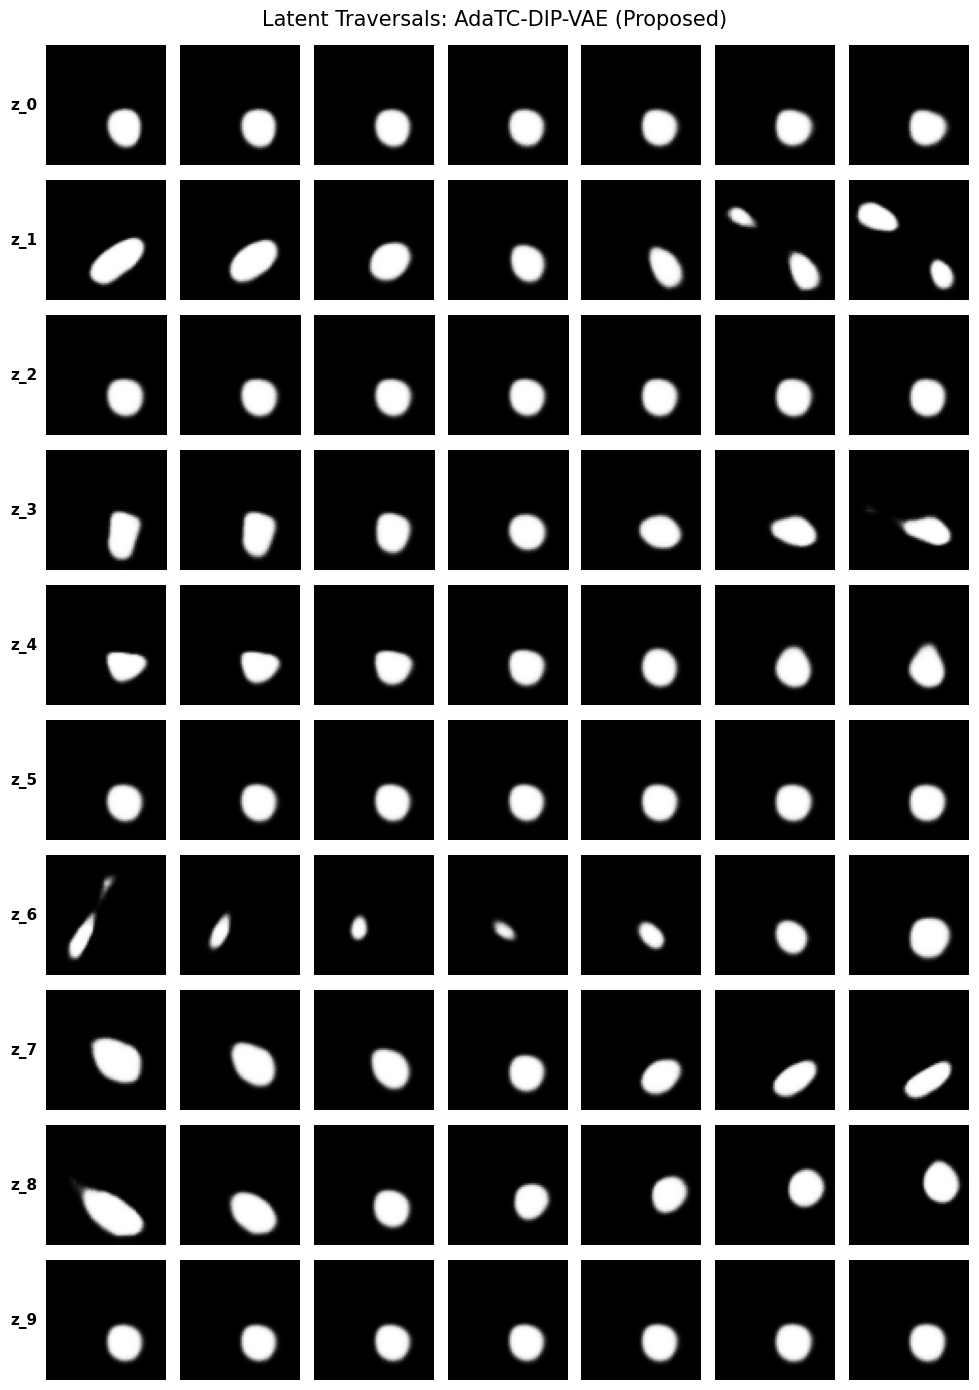

In [13]:
# Pick representative test image
test_sample = eval_imgs[20]

plot_latent_traversals(
    models_dict={"AdaTC-DIP-VAE (Proposed)": model_adatc_dip},
    sample_img=test_sample,
    device=device,
    num_steps=7,
    val_range=(-3.0, 3.0),
    save_path="traversals_proposed.png"
)

